# УИР 1 · Статистический анализ последовательности
##### **Дисциплина:** моделирование

##### **Вариант:** 283

##### **Выполнил:** Коршун Артём P3319 466300

## 1. Цель работы
Изучение методов обработки и статистического анализа результатов
измерений на примере заданной числовой последовательности путем оценки
числовых моментов и выявления свойств последовательности на основе
корреляционного анализа, а также аппроксимация закона распределения заданной
последовательности по двум числовым моментам случайной величины.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SIZES = [10, 20, 50, 100, 200, 300]
Z = {"ci90": 1.643, "ci95": 1.960, "ci99": 2.576}
BLUE, ORANGE = "#389BFF", "#FF8432"

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.18,
    "figure.dpi": 120,
})


## 2. Исходные данные
Для каждого объёма берём первые 10, 20, 50, 100, 200 и 300 чисел,
сохраняя их порядок. 

Выбросы не удаляем так как они влияют на среднее и дисперсию.


In [2]:
raw_data = """
59,861 9,353 4,713 4,612 6,480 7,944 5,281 5,345 9,208 8,823
4,709 4,723 6,556 58,414 5,837 25,020 5,111 7,895 7,199 4,613
4,605 9,218 8,356 7,548 4,927 5,520 5,226 5,172 9,046 4,612
6,928 5,446 9,727 7,955 7,143 4,678 5,083 4,617 6,357 35,720
44,366 30,174 5,299 4,663 9,753 6,803 7,795 4,951 9,808 64,711
7,347 5,392 5,702 6,983 6,212 9,174 27,790 4,795 66,733 9,765
6,642 4,699 6,573 4,606 5,962 7,981 4,606 4,644 6,978 4,620
5,710 4,668 5,625 9,856 8,332 8,021 5,978 23,256 6,298 7,775
4,641 9,242 9,978 7,849 4,727 9,405 8,045 6,411 8,947 17,262
5,367 6,066 5,265 4,635 7,116 181,252 4,872 7,614 4,669 4,740
8,632 6,254 7,331 5,143 5,077 100,110 8,083 8,430 41,194 7,341
5,678 8,859 9,402 17,835 6,487 6,020 8,206 9,029 4,878 5,638
4,610 4,942 6,006 4,620 8,555 8,734 5,933 6,741 6,234 7,322
6,730 7,444 5,519 14,038 4,769 5,278 16,644 4,654 69,469 5,868
7,427 5,499 67,009 9,695 18,274 4,843 7,720 9,442 4,864 8,161
7,922 8,372 4,698 5,074 9,657 4,657 7,346 4,790 5,050 6,084
7,031 8,664 5,200 7,843 5,815 4,962 16,078 85,836 9,080 7,401
6,918 5,205 7,763 6,730 4,612 16,355 8,366 6,471 7,874 7,951
45,538 4,958 6,261 4,694 4,620 5,469 8,122 5,350 6,331 4,625
4,689 5,313 8,662 5,298 6,277 7,481 4,727 4,841 6,760 25,568
8,507 4,618 4,645 66,065 9,743 33,363 6,370 5,741 6,419 7,227
9,655 15,373 27,791 5,054 5,830 5,376 5,716 8,504 6,137 4,616
4,990 26,255 5,734 4,794 6,916 6,603 8,313 8,762 44,623 4,635
8,701 49,373 9,202 9,323 6,979 5,806 5,870 9,718 4,688 5,036
5,547 7,466 7,426 4,655 6,942 5,091 4,613 8,505 4,892 96,434
9,508 7,216 9,550 4,978 8,891 273,304 66,930 9,270 23,932 4,667
20,449 5,279 5,789 4,640 7,568 5,324 6,621 5,334 4,696 5,320
8,911 9,484 6,037 7,426 8,122 66,734 4,624 4,951 5,987 5,497
49,820 5,431 8,347 9,310 5,475 4,875 48,320 8,367 7,079 5,407
4,606 9,488 4,757 8,129 4,895 5,791 5,907 29,795 4,961 5,813
"""
x = np.array([float(value.replace(",", ".")) for value in raw_data.split()])
assert len(x) == 300 and np.all(np.isfinite(x)) and np.all(x > 0)

print(f"Наблюдений: {len(x)}; минимум: {x.min():.3f}; максимум: {x.max():.3f}")
print(f"Медиана: {np.median(x):.4f}; сумма: {x.sum():.3f}")
display(pd.DataFrame({"Номер": np.arange(1, 11), "Исходное значение": x[:10]})
        .set_index("Номер").T.style.format(precision=3, decimal=","))


Наблюдений: 300; минимум: 4.605; максимум: 273.304
Медиана: 6.6315; сумма: 3799.044


Номер,1,2,3,4,5,6,7,8,9,10
Исходное значение,"59,861","9,353","4,713","4,612","6,480","7,944","5,281","5,345","9,208","8,823"


## 2. Что рассчитываем
Для выборки из $n$ значений:

$$m=\frac{1}{n}\sum_{i=1}^{n}x_i,\qquad
s^2=\frac{1}{n-1}\sum_{i=1}^{n}(x_i-m)^2,\qquad
s=\sqrt{s^2},\qquad CV=\frac{s}{m}.$$

$m$ — оценка среднего, 

$s^2$ — исправленная дисперсия, 

$s$ — СКО.
Деление на $n-1$ даёт несмещённую оценку дисперсии.

$CV$ - коэффициент вариации.

Приближённый доверительный интервал среднего:

$$[m-\varepsilon_\gamma;\ m+\varepsilon_\gamma],\qquad
\varepsilon_\gamma=z_\gamma\frac{s}{\sqrt n}.$$

Нужно рассчитать доверительные интервалы для оценки мат. ожидания
с доверительными вероятностями 0,9; 0,95 и 0,99. 

Коэффициенты из методички: $z_{0,9}=1{,}643$, $z_{0,95}=1{,}960$,
$z_{0,99}=2{,}576$. В таблицах записываем полуинтервал $\pm\varepsilon$.



In [3]:
def statistics(values):
    mean = float(np.mean(values))
    variance = float(np.var(values, ddof=1))
    std = variance**0.5
    return {
        "n": len(values), "mean": mean, "variance": variance,
        "std": std, "cv": std / mean,
        **{name: z * std / len(values)**0.5 for name, z in Z.items()},
    }


def deviations(row, reference):
    return {
        name: value if name == "n" else
        100 * abs(value - reference[name]) / abs(reference[name])
        for name, value in row.items()
    }


### Таблицы исходной выборки
Эталон — характеристики всех 300 исходных значений. Для каждой характеристики
$A$ считаем относительное отклонение:

$$\delta_A(n)=100\%\cdot\frac{|A_n-A_{300}|}{|A_{300}|}.$$

Отклонения доверительных интервалов относятся к их полуширинам.
Ноль в последнем столбце получается по определению эталона.


In [ ]:
original = pd.DataFrame([statistics(x[:n]) for n in SIZES])
reference = original.iloc[-1].to_dict()
delta_original = pd.DataFrame([
    deviations(row, reference) for row in original.to_dict("records")
])

characteristics = ["mean", "ci90", "ci95", "ci99", "variance", "std", "cv"]
labels = {
    "mean": "Среднее m", "ci90": "ДИ 90%", "ci95": "ДИ 95%",
    "ci99": "ДИ 99%", "variance": "Дисперсия s²", "std": "СКО s",
    "cv": "Коэффициент вариации",
}
interval_rows = [labels[name] for name in Z]

original_table = original.set_index("n")[characteristics].rename(columns=labels).T
display(original_table.style.format(precision=5, decimal=",")
        .format(lambda value: f"± {value:.5f}".replace(".", ","),
                subset=pd.IndexSlice[interval_rows, :])
        .set_caption("Исходная последовательность: значения характеристик"))
display(delta_original.set_index("n")[characteristics].rename(columns=labels).T
        .style.format(precision=2, decimal=",")
        .set_caption("Отклонения от исходной выборки n = 300, %"))


n,10,20,50,100,200,300
Среднее m,"12,16200","12,58485","11,95808","12,08730","11,55395","12,66348"
ДИ 90%,"± 8,76155","± 6,07326","± 3,44412","± 3,47472","± 2,16153","± 2,21169"
ДИ 95%,"± 10,45200","± 7,24503","± 4,10863","± 4,14513","± 2,57858","± 2,63841"
ДИ 99%,"± 13,73691","± 9,52204","± 5,39991","± 5,44788","± 3,38899","± 3,46762"
Дисперсия s²,"284,37184","273,27408","219,71095","447,26383","346,16164","543,61780"
СКО s,"16,86333","16,53100","14,82265","21,14861","18,60542","23,31561"
Коэффициент вариации CV,"1,38656","1,31356","1,23955","1,74966","1,61031","1,84117"


n,10,20,50,100,200,300
Среднее m,"3,96","0,62","5,57","4,55","8,76","0,00"
ДИ 90%,"296,15","174,60","55,72","57,11","2,27","0,00"
ДИ 95%,"296,15","174,60","55,72","57,11","2,27","0,00"
ДИ 99%,"296,15","174,60","55,72","57,11","2,27","0,00"
Дисперсия s²,"47,69","49,73","59,58","17,72","36,32","0,00"
СКО s,"27,67","29,10","36,43","9,29","20,20","0,00"
Коэффициент вариации CV,"24,69","28,66","32,68","4,97","12,54","0,00"


Вывод. Для 300 наблюдений $m=12{,}66348$, $s^2=543{,}61780$,
$s=23{,}31561$, $CV=1{,}84117$.

95%-й приближённый интервал среднего — [10,02507; 15,30189].

Среднее меняется слабее дисперсии: редкие большие значения заметно увеличивают разброс.

Оценки и ширины интервалов не обязаны изменяться монотонно при добавлении наблюдений.


## 3. Порядок наблюдений
График «номер → значение» позволяет увидеть рост, спад и повторяющиеся колебания.
Пунктир — среднее всех 300 значений. Дополнительно считаем корреляцию значения
с его номером: она описывает линейную тенденцию.


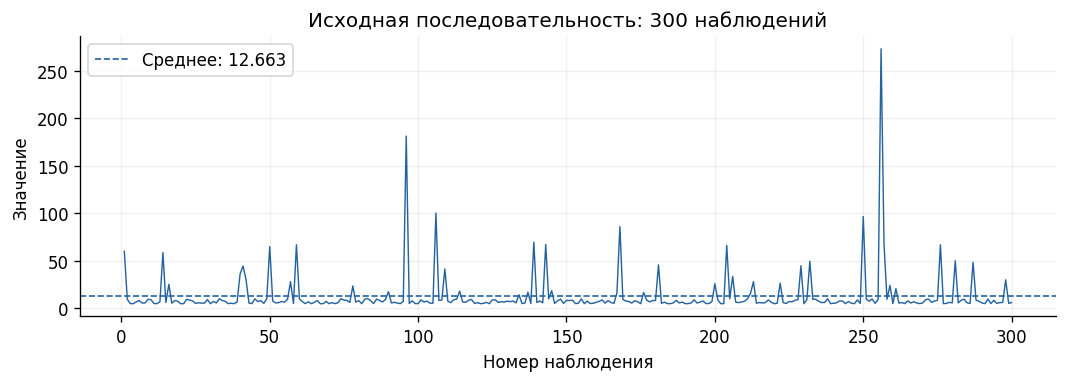

Корреляция значения с номером: 0.04502


In [5]:
fig, ax = plt.subplots(figsize=(9, 3.3))
ax.plot(np.arange(1, len(x) + 1), x, color=BLUE, linewidth=0.85)
ax.axhline(x.mean(), color=BLUE, linestyle="--", linewidth=1,
           label=f"Среднее: {x.mean():.3f}")
ax.set(xlabel="Номер наблюдения", ylabel="Значение",
       title="Исходная последовательность: 300 наблюдений")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

trend_r = float(np.corrcoef(np.arange(len(x)), x)[0, 1])
print(f"Корреляция значения с номером: {trend_r:.5f}")


Вывод. Выраженного роста или спада нет: корреляция с номером равна 0,04502.
Встречаются отдельные большие всплески. Устойчивой периодичности на графике
не видно, поэтому обоснованную длину периода указать нельзя.


## 4. Гистограмма исходных значений
Слева — все данные, справа — увеличение области 0–20 с более узкими интервалами.
Столбцы показывают число наблюдений. Во втором графике меняется только масштаб:
большие значения сохраняются в данных, хотя не попадают в видимую область.


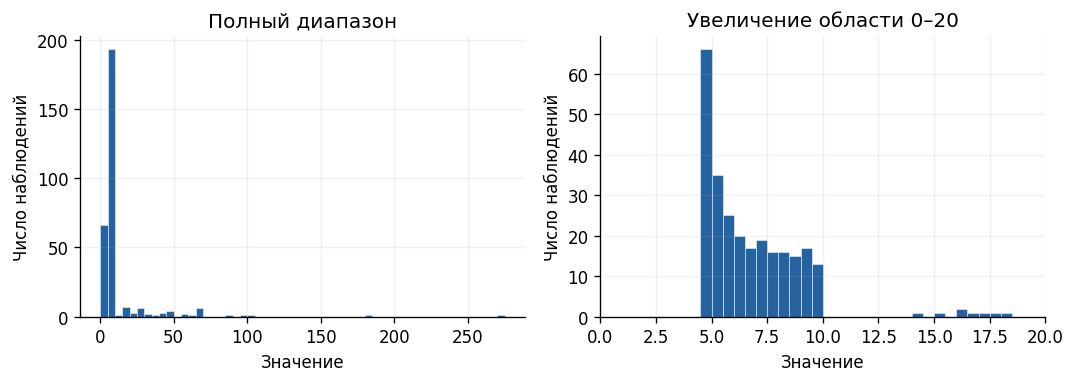

In [ ]:
fine_bins = np.arange(0, np.ceil(x.max()) + 1, 0.5)
coarse_bins = np.arange(0, np.ceil(x.max() / 5) * 5 + 5, 5)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
for ax, bins, limit in zip(axes, [coarse_bins, fine_bins], [None, 20]):
    ax.hist(x, bins=bins, color=BLUE, edgecolor="white", linewidth=0.3)
    if limit is not None:
        ax.set_xlim(0, limit)
    ax.set(xlabel="Значение", ylabel="Число наблюдений",
           title="Полный диапазон" if limit is None else "0–20")
fig.tight_layout()
plt.show()


Вывод. Большинство значений сосредоточено около 4,6–10, а правый хвост
тянется до 273,304. Медиана 6,6315 существенно ниже среднего
12,66348: распределение асимметрично вправо. Большие значения сохраняем при расчётах.


## 5. Автокорреляция исходной последовательности
Для сдвига $k$ считаем корреляцию Пирсона между двумя отрезками:
$(x_1,\ldots,x_{n-k})$ и $(x_{1+k},\ldots,x_n)$.
У каждого отрезка своё среднее:

$$r_k=\frac{\sum_{i=1}^{n-k}(x_i-\bar x_a)(x_{i+k}-\bar x_b)}
{\sqrt{\sum_{i=1}^{n-k}(x_i-\bar x_a)^2\sum_{i=1}^{n-k}(x_{i+k}-\bar x_b)^2}}.$$

Проверяем сдвиги 1–10. Пунктир $\pm1{,}96/\sqrt{300}$ — приблизительный
ориентир для отдельных коэффициентов при отсутствии зависимости.
Он не является строгой совместной проверкой всех десяти сдвигов.


In [7]:
def autocorrelation(values):
    return np.array([
        float(np.corrcoef(values[:-k], values[k:])[0, 1])
        for k in range(1, 11)
    ])


lags = np.arange(1, 11)
ac_x = autocorrelation(x)
bound = 1.96 / len(x)**0.5

display(pd.DataFrame({"Сдвиг k": lags, "rₖ исходной": ac_x})
        .set_index("Сдвиг k").T.style.format(precision=5, decimal=","))
print(f"Ориентир: ±{bound:.5f}")


Сдвиг k,1,2,3,4,5,6,7,8,9,10
rₖ исходной,"0,05965","-0,02297","-0,01013","-0,03442","-0,00843","0,11409","-0,02027","-0,04272","-0,01211","0,03866"


Ориентир: ±0.11316


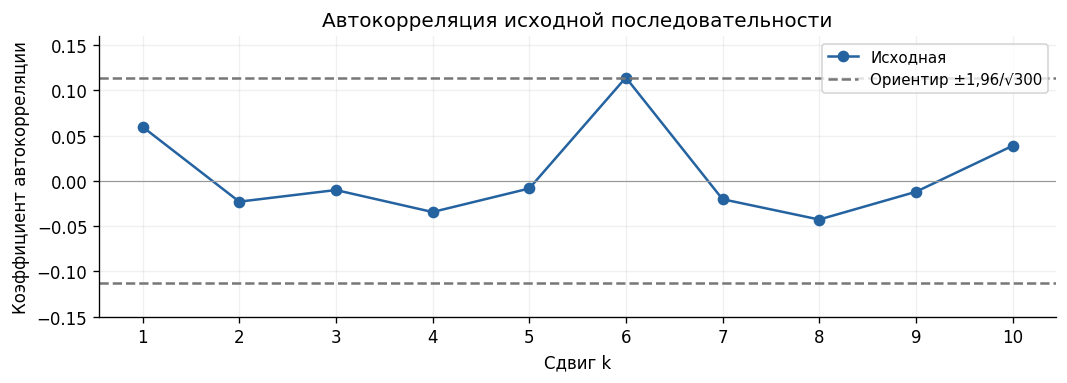

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.3))
ax.plot(lags, ac_x, "o-", color=BLUE, label="Исходная")
ax.axhline(bound, color="#777777", linestyle="--", label="Ориентир ±1,96/√300")
ax.axhline(-bound, color="#777777", linestyle="--")
ax.axhline(0, color="#999999", linewidth=0.7)
ax.set(xlabel="Сдвиг k", ylabel="Коэффициент автокорреляции",
       title="Автокорреляция исходной последовательности", xticks=lags,
       ylim=(-0.15, 0.16))
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
plt.show()


Вывод. Все коэффициенты невелики. На сдвиге 6 получено 0,11409,
что чуть выше ориентира 0,11316. Один слабый пик при десяти проверках
не доказывает периодичность. Для моделирования можно принять последовательность
случайной: устойчивой линейной зависимости на сдвигах 1–10 не обнаружено.
Это не является доказательством независимости.


## 6. Аппроксимация по двум моментам
Для исходной выборки $CV=1{,}84117>1$. Выбираем гиперэкспоненциальное
распределение $H_2$: смесь двух экспоненциальных законов.
С вероятностью $p$ используется первая ветвь, с вероятностью $1-p$ вторая.

Плотность распределения:

$$f(x)=p\lambda_1e^{-\lambda_1x}+(1-p)\lambda_2e^{-\lambda_2x},\qquad x\geq0.$$

$f(x)$ - плотность распределения.

$x$ - возможное значение случайной величины.

$p$ - вероятность выбора первой ветви.

$\lambda_1$, $\lambda_2$ - интенсивности экспоненциальных законов.

$1/\lambda_1$, $1/\lambda_2$ - средние значения в первой и второй ветвях.

Параметры подбираем по среднему и исправленной дисперсии исходных 300 значений:

$$E[X]=\frac{p}{\lambda_1}+\frac{1-p}{\lambda_2}=m,$$

$$E[X^2]=\frac{2p}{\lambda_1^2}+\frac{2(1-p)}{\lambda_2^2}=m^2+s^2.$$

$X$ - случайная величина с выбранным распределением.

$E[X]$ - теоретическое среднее модели.

$E[X^2]$ - второй начальный момент, то есть среднее квадрата случайной величины.

$m$ - среднее исходной выборки.

$s^2$ - исправленная дисперсия исходной выборки.

$m^2+s^2$ - принятая оценка второго начального момента. Она отличается
от среднего квадратов наблюдений, поскольку $s^2$ рассчитана с делением на $n-1$.

Два момента дают два уравнения для трёх параметров. Добавляем условие
равных вкладов ветвей в среднее:

$$\frac{p}{\lambda_1}=\frac{1-p}{\lambda_2}=\frac{m}{2}.$$

Получаем:

$$p=\frac{1+\sqrt{(CV^2-1)/(CV^2+1)}}{2},\qquad
\lambda_1=\frac{2p}{m},\qquad \lambda_2=\frac{2(1-p)}{m}.$$

$CV=s/m$ - коэффициент вариации исходной выборки.


In [9]:
mean = reference["mean"]
variance = reference["variance"]
cv2 = variance / mean**2
assert cv2 > 1, "Для этой аппроксимации H₂ требуется CV > 1"
p = (1 + ((cv2 - 1) / (cv2 + 1))**0.5) / 2
lambda1 = 2 * p / mean
lambda2 = 2 * (1 - p) / mean

model_mean = p / lambda1 + (1 - p) / lambda2
model_second_moment = 2 * p / lambda1**2 + 2 * (1 - p) / lambda2**2
model_variance = model_second_moment - model_mean**2

display(pd.DataFrame({
    "Параметр": ["p", "1 - p", "λ₁", "λ₂", "1/λ₁", "1/λ₂",
                 "m² + s²", "Среднее модели", "Дисперсия модели"],
    "Значение": [p, 1 - p, lambda1, lambda2, 1 / lambda1, 1 / lambda2,
                 mean**2 + variance, model_mean, model_variance],
}).set_index("Параметр").style.format(precision=6, decimal=","))


,Значение
Параметр,
p,"0,868920"
1 - p,"0,131080"
λ₁,"0,137232"
λ₂,"0,020702"
1/λ₁,"7,286904"
1/λ₂,"48,304571"
m² + s²,"703,981524"
Среднее модели,"12,663480"
Дисперсия модели,"543,617798"


Вывод. $p=0{,}868920$, $\lambda_1=0{,}137232$, $\lambda_2=0{,}020702$.
Первая ветвь выбирается с вероятностью около 86,89% и имеет среднее 7,28690.
Среднее второй ветви равно 48,30457. Она выбирается реже и создаёт длинный правый хвост.
Среднее и дисперсия модели совпадают с оценками исходной выборки.

### Плотность модели и исходная гистограмма
По горизонтали откладываем значение, по вертикали плотность.
Площадь всей гистограммы равна 1, поэтому её можно сравнивать с плотностью $f(x)$.
Слева показан полный диапазон, справа участок от 0 до 20.


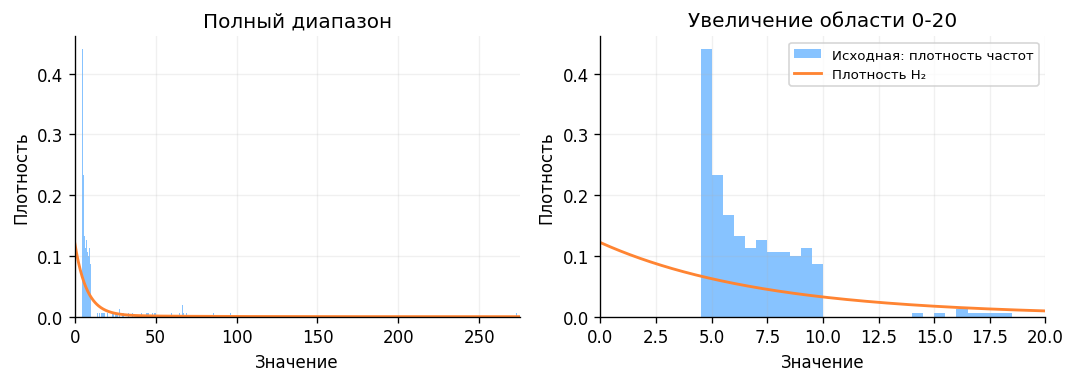

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
for ax, limit in zip(axes, [float(coarse_bins[-1]), 20]):
    ax.hist(x, bins=fine_bins, density=True, color=BLUE, alpha=0.6,
            label="Исходная: плотность частот")
    grid = np.linspace(0, limit, 1200)
    pdf = p * lambda1 * np.exp(-lambda1 * grid) + (1 - p) * lambda2 * np.exp(-lambda2 * grid)
    ax.plot(grid, pdf, color=ORANGE, linewidth=1.7, label="Плотность H₂")
    ax.set(xlim=(0, limit), xlabel="Значение", ylabel="Плотность",
           title="Полный диапазон" if limit > 20 else "Увеличение области 0-20")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()


Вывод. Плотность H₂ максимальна в нуле. В исходной выборке минимальное значение
равно 4,605, а большинство наблюдений находится между 4,6 и 10.
Модель описывает длинный правый хвост, но плохо воспроизводит основную область
гистограммы. Совпадения среднего и дисперсии недостаточно для совпадения формы распределения.


## 7. Генерация новой последовательности
Генерируем 300 значений. Для каждого значения выполняем два шага:

1. Получаем равномерное случайное число $U$ от 0 до 1. Если $U<p$,
   выбираем первую ветвь, иначе вторую.
2. Получаем экспоненциальное случайное значение с интенсивностью выбранной ветви.

$U$ - число для выбора ветви.

$p$ - вероятность выбора первой ветви, найденная в пункте 6.

В `rng.exponential` передаём среднее выбранной ветви $1/\lambda$.
Параметр `SEED = 42` фиксирует начальное состояние генератора
и позволяет повторить ту же последовательность.


In [11]:
SEED = 42
rng = np.random.default_rng(SEED)
first_branch = rng.random(len(x)) < p
rates = np.where(first_branch, lambda1, lambda2)
y = rng.exponential(1 / rates)

print(f"Сгенерировано {len(y)} значений; SEED = {SEED}")
display(pd.DataFrame({"Номер": np.arange(1, 11), "Новое значение": y[:10]})
        .set_index("Номер").T.style.format(precision=5, decimal=","))


Сгенерировано 300 значений; SEED = 42


Номер,1,2,3,4,5,6,7,8,9,10
Новое значение,"7,99261","1,40300","8,49400","1,21604","7,20793","37,06206","2,60554","5,17475","6,57464","1,68850"


## 8. Характеристики новой последовательности
Для первых 10, 20, 50, 100, 200 и 300 новых значений считаем среднее,
исправленную дисперсию, СКО, коэффициент вариации и доверительные интервалы.
Используем формулы пункта 2.

Сравниваем новую и исходную выборки одного объёма:

$$\delta_A(n)=\frac{|A_n^{\mathrm{ген}}-A_n^{\mathrm{исх}}|}
{|A_n^{\mathrm{исх}}|}\cdot100\%.$$

$n$ - количество сравниваемых значений.

$A$ - сравниваемая характеристика: среднее, дисперсия, СКО, коэффициент вариации
или число после знака $\pm$ в записи доверительного интервала.

$A_n^{\mathrm{ген}}$ - характеристика первых $n$ сгенерированных значений.

$A_n^{\mathrm{исх}}$ - та же характеристика первых $n$ исходных значений.

$\delta_A(n)$ - относительное отклонение в процентах.

Например, среднее первых 10 новых значений сравниваем со средним первых 10
исходных значений. В строках «ДИ» сравниваем числа после $\pm$,
то есть половины ширины соответствующих доверительных интервалов.


In [12]:
generated = pd.DataFrame([statistics(y[:n]) for n in SIZES])
delta_generated = pd.DataFrame([
    deviations(new, old)
    for new, old in zip(generated.to_dict("records"), original.to_dict("records"))
])

generated_table = generated.set_index("n")[characteristics].rename(columns=labels).T
display(generated_table.style.format(precision=5, decimal=",")
        .format(lambda value: f"± {value:.5f}".replace(".", ","),
                subset=pd.IndexSlice[interval_rows, :])
        .set_caption(f"Сгенерированная H₂: значения характеристик, SEED = {SEED}"))
display(delta_generated.set_index("n")[characteristics].rename(columns=labels).T
        .style.format(precision=2, decimal=",")
        .set_caption("Отклонения от исходной выборки того же объёма, %"))


n,10,20,50,100,200,300
Среднее m,"7,94191","7,09773","9,72387","9,60056","10,86085","11,75021"
ДИ 90%,"± 5,51469","± 3,05930","± 2,49152","± 1,58233","± 1,76129","± 1,93250"
ДИ 95%,"± 6,57869","± 3,64956","± 2,97223","± 1,88762","± 2,10111","± 2,30536"
ДИ 99%,"± 8,64628","± 4,79656","± 3,90636","± 2,48087","± 2,76146","± 3,02990"
Дисперсия s²,"112,65919","69,34234","114,98026","92,75079","229,83445","415,03649"
СКО s,"10,61410","8,32720","10,72289","9,63072","15,16029","20,37244"
Коэффициент вариации,"1,33647","1,17322","1,10274","1,00314","1,39587","1,73379"


n,10,20,50,100,200,300
Среднее m,"34,70","43,60","18,68","20,57","6,00","7,21"
ДИ 90%,"37,06","49,63","27,66","54,46","18,52","12,62"
ДИ 95%,"37,06","49,63","27,66","54,46","18,52","12,62"
ДИ 99%,"37,06","49,63","27,66","54,46","18,52","12,62"
Дисперсия s²,"60,38","74,63","47,67","79,26","33,60","23,65"
СКО s,"37,06","49,63","27,66","54,46","18,52","12,62"
Коэффициент вариации,"3,61","10,68","11,04","42,67","13,32","5,83"


In [13]:
gen_full = generated.iloc[-1]
delta_full = delta_generated.iloc[-1]
display(Markdown(
    f"Вывод. Для 300 новых значений среднее равно {gen_full['mean']:.5f}, "
    f"исправленная дисперсия {gen_full['variance']:.5f}. "
    f"Отклонение среднего от исходной выборки составляет {delta_full['mean']:.2f}%, "
    f"дисперсии {delta_full['variance']:.2f}%. "
    "Теоретические среднее и дисперсия H₂ совпадают с исходными оценками, "
    "но оценки по 300 сгенерированным значениям отличаются из-за случайности выборки. "
    "Редкие большие значения особенно влияют на дисперсию."
))


Вывод. Для 300 новых значений среднее равно 11.75021, исправленная дисперсия 415.03649. Отклонение среднего от исходной выборки составляет 7.21%, дисперсии 23.65%. Теоретические среднее и дисперсия H₂ совпадают с исходными оценками, но оценки по 300 сгенерированным значениям отличаются из-за случайности выборки. Редкие большие значения особенно влияют на дисперсию.

## 9. Сравнение графиков и гистограмм
На графиках по горизонтали откладываем номер наблюдения, по вертикали его значение.
Используем одинаковые шкалы для обеих последовательностей.
Пунктир показывает среднее каждой выборки.


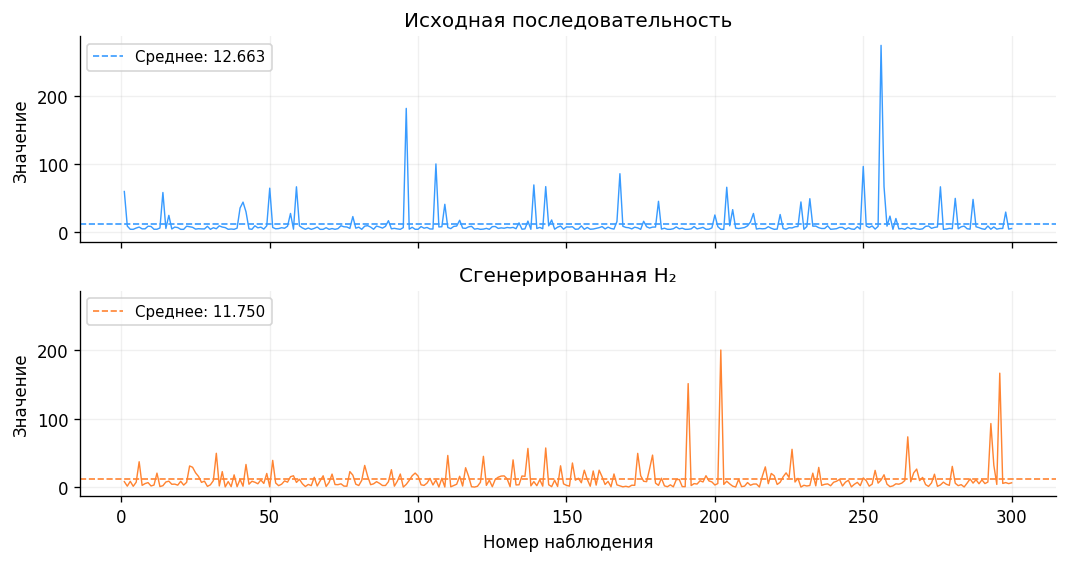

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(9, 4.8), sharex=True, sharey=True)
for ax, values, color, title in zip(
    axes, [x, y], [BLUE, ORANGE], ["Исходная последовательность", "Сгенерированная H₂"]
):
    ax.plot(np.arange(1, len(values) + 1), values, color=color, linewidth=0.85)
    ax.axhline(values.mean(), color=color, linestyle="--", linewidth=1,
               label=f"Среднее: {values.mean():.3f}")
    ax.set(ylabel="Значение", title=title)
    ax.legend(loc="upper left", fontsize=9)
axes[-1].set_xlabel("Номер наблюдения")
fig.tight_layout()
plt.show()


In [15]:
display(Markdown(
    f"Вывод. Значения исходной последовательности лежат от {x.min():.3f} "
    f"до {x.max():.3f}, новой от {y.min():.3f} до {y.max():.3f}. "
    "В обеих последовательностях встречаются редкие большие значения. "
    "В новой выборке также появились значения, близкие к нулю, "
    "которых нет в исходных данных."
))


Вывод. Значения исходной последовательности лежат от 4.605 до 273.304, новой от 0.065 до 200.199. В обеих последовательностях встречаются редкие большие значения. В новой выборке также появились значения, близкие к нулю, которых нет в исходных данных.

### Сравнение гистограмм
Для обеих выборок используем одинаковые интервалы группировки.
Площадь каждой полной гистограммы равна 1.
Слева показан полный диапазон, справа участок от 0 до 20.
Данные за пределами правого графика сохраняются при расчёте плотности.


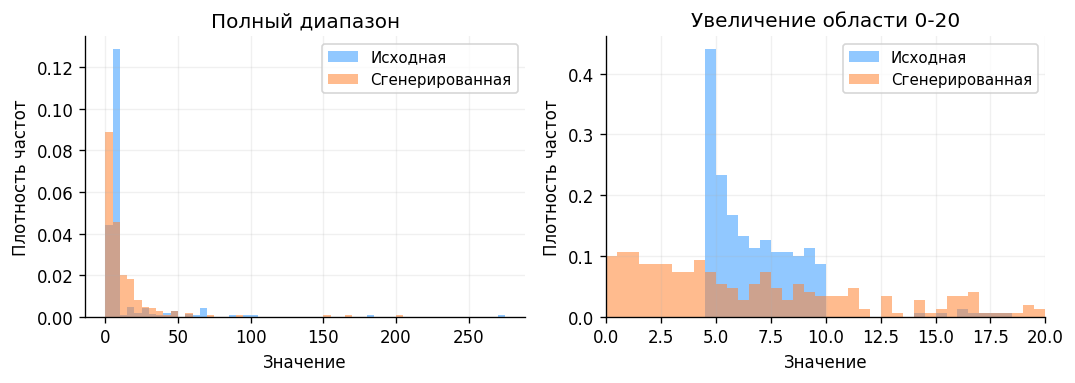

In [16]:
fine_bins = np.arange(0, np.ceil(max(x.max(), y.max())) + 1, 0.5)
coarse_bins = np.arange(0, np.ceil(max(x.max(), y.max()) / 5) * 5 + 5, 5)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
for ax, bins, limit in zip(axes, [coarse_bins, fine_bins], [None, 20]):
    ax.hist(x, bins=bins, density=True, color=BLUE, alpha=0.55, label="Исходная")
    ax.hist(y, bins=bins, density=True, color=ORANGE, alpha=0.55, label="Сгенерированная")
    if limit is not None:
        ax.set_xlim(0, limit)
    ax.set(xlabel="Значение", ylabel="Плотность частот",
           title="Полный диапазон" if limit is None else "Увеличение области 0-20")
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()


Вывод. Исходные значения сосредоточены между 4,6 и 10.
Новая выборка содержит много значений ниже 4,605.
Несмотря на длинный правый хвост у обеих выборок, формы гистограмм заметно различаются.


## 10. Автокорреляция новой последовательности
Для сдвигов от 1 до 10 считаем коэффициенты автокорреляции по формуле пункта 5.
Сравниваем их с коэффициентами исходной последовательности:

$$\delta_{r_k}=\frac{|r_k^{\mathrm{ген}}-r_k^{\mathrm{исх}}|}
{|r_k^{\mathrm{исх}}|}\cdot100\%.$$

$k$ - сдвиг, то есть расстояние между сравниваемыми позициями в списке.

$r_k^{\mathrm{ген}}$ - коэффициент автокорреляции новой последовательности при сдвиге $k$.

$r_k^{\mathrm{исх}}$ - коэффициент автокорреляции исходной последовательности при том же сдвиге.

$\delta_{r_k}$ - относительное отклонение в процентах.

Если исходный коэффициент близок к нулю, деление на него даёт большой процент
даже при небольшой разнице коэффициентов. Поэтому учитываем также
сами коэффициенты и их положение относительно ориентира $\pm1{,}96/\sqrt{300}$.


Сдвиг k,1,2,3,4,5,6,7,8,9,10
rₖ исходной,"0,05965","-0,02297","-0,01013","-0,03442","-0,00843","0,11409","-0,02027","-0,04272","-0,01211","0,03866"
rₖ сгенерированной,"-0,05939","-0,01229","0,05239","-0,04206","-0,03998","0,00783","-0,05826","-0,04893","-0,00838","-0,07105"
"Отклонение, %","199,57","46,51","617,24","22,20","373,95","93,14","187,46","14,53","30,80","283,76"


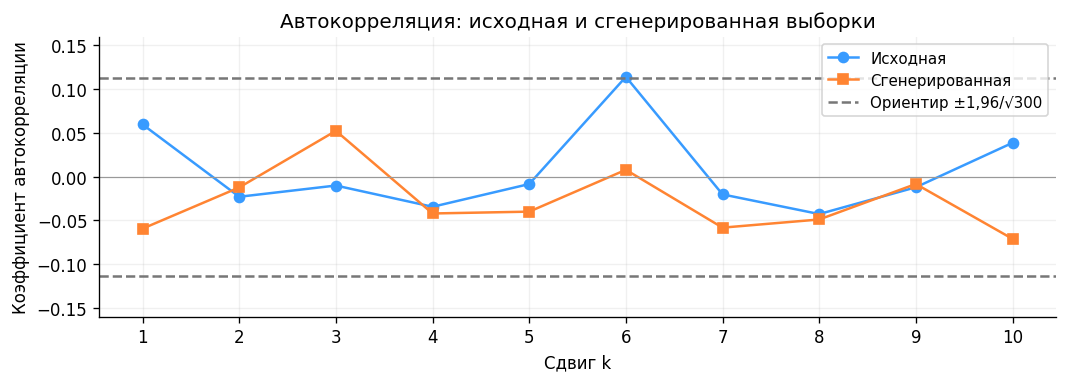

In [17]:
ac_y = autocorrelation(y)
ac_percent = 100 * np.abs(ac_y - ac_x) / np.abs(ac_x)
ac_table = pd.DataFrame({
    "Сдвиг k": lags, "rₖ исходной": ac_x,
    "rₖ сгенерированной": ac_y, "Отклонение, %": ac_percent,
}).set_index("Сдвиг k").T
display(ac_table.style.format(precision=5, decimal=",")
        .format(precision=2, decimal=",", subset=pd.IndexSlice[["Отклонение, %"], :])
        .set_caption("Коэффициенты автокорреляции: форма 3"))

fig, ax = plt.subplots(figsize=(9, 3.3))
ax.plot(lags, ac_x, "o-", color=BLUE, label="Исходная")
ax.plot(lags, ac_y, "s-", color=ORANGE, label="Сгенерированная")
ax.axhline(bound, color="#777777", linestyle="--", label="Ориентир ±1,96/√300")
ax.axhline(-bound, color="#777777", linestyle="--")
ax.axhline(0, color="#999999", linewidth=0.7)
plot_bound = max(0.16, np.max(np.abs(ac_y)) * 1.25)
ax.set(xlabel="Сдвиг k", ylabel="Коэффициент автокорреляции",
       title="Автокорреляция: исходная и сгенерированная выборки", xticks=lags,
       ylim=(-plot_bound, plot_bound))
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
plt.show()


In [18]:
peak_lag = int(np.argmax(np.abs(ac_y))) + 1
outside_count = int(np.sum(np.abs(ac_y) > bound))
display(Markdown(
    f"Вывод. В новой последовательности наибольший по модулю коэффициент "
    f"равен {ac_y[peak_lag - 1]:.5f} при сдвиге {peak_lag}. "
    f"За ориентир ±{bound:.5f} выходят {outside_count} из 10 коэффициентов. "
    "На проверенных сдвигах устойчивой линейной зависимости не обнаружено. "
    "Для моделирования новую последовательность можно считать случайной. "
    "Большие процентные отклонения коэффициентов около нуля "
    "не означают сильной зависимости."
))


Вывод. В новой последовательности наибольший по модулю коэффициент равен -0.07105 при сдвиге 10. За ориентир ±0.11316 выходят 0 из 10 коэффициентов. На проверенных сдвигах устойчивой линейной зависимости не обнаружено. Для моделирования новую последовательность можно считать случайной. Большие процентные отклонения коэффициентов около нуля не означают сильной зависимости.

## 11. Корреляция двух последовательностей и качество модели
Считаем корреляцию Пирсона между парами $(x_1,y_1)$, $(x_2,y_2)$ и так далее.

$x_i$ - исходное значение с номером $i$.

$y_i$ - сгенерированное значение с тем же номером.

$r_{XY}$ - коэффициент корреляции двух последовательностей.

Он показывает линейную связь между значениями с одинаковыми номерами.
По этому коэффициенту нельзя определить, похожи ли распределения.

Для оценки качества модели дополнительно находим вероятность получить значение
ниже минимума исходной выборки:

$$P(Y<a)=1-pe^{-\lambda_1a}-(1-p)e^{-\lambda_2a}.$$

$Y$ - случайная величина с распределением H₂.

$a=4{,}605$ - минимальное исходное значение.

$P(Y<a)$ - вероятность, что сгенерированное значение окажется меньше $a$.

$p$, $\lambda_1$, $\lambda_2$ - параметры модели из пункта 6.


In [19]:
corr_xy = float(np.corrcoef(x, y)[0, 1])
prob_below_min = float(
    1 - p * np.exp(-lambda1 * x.min()) - (1 - p) * np.exp(-lambda2 * x.min())
)
generated_below_min = int(np.sum(y < x.min()))

display(Markdown(
    f"Вывод. Корреляция двух последовательностей равна {corr_xy:.5f}. "
    "Выраженной линейной связи между значениями с одинаковыми номерами нет.\n\n"
    f"Вероятность получить значение ниже {x.min():.3f} по модели "
    f"составляет {100 * prob_below_min:.2f}%. "
    f"В новой выборке таких значений {generated_below_min} из {len(y)}, "
    f"то есть {100 * generated_below_min / len(y):.2f}%. "
    "В исходной выборке таких значений нет. "
    "Модель согласована со средним и дисперсией, "
    "но форма исходного распределения воспроизводится плохо."
))


Вывод. Корреляция двух последовательностей равна -0.04050. Выраженной линейной связи между значениями с одинаковыми номерами нет.

Вероятность получить значение ниже 4.605 по модели составляет 41.90%. В новой выборке таких значений 123 из 300, то есть 41.00%. В исходной выборке таких значений нет. Модель согласована со средним и дисперсией, но форма исходного распределения воспроизводится плохо.

## 12. Выводы


In [20]:
display(Markdown(f"""
Для 300 исходных наблюдений получены среднее {reference['mean']:.5f},
исправленная дисперсия {reference['variance']:.5f}, СКО {reference['std']:.5f}
и коэффициент вариации {reference['cv']:.5f}. Выраженного линейного тренда
и устойчивой автокорреляции на сдвигах от 1 до 10 не обнаружено.
Для моделирования исходную последовательность можно считать случайной.

По двум моментам построено гиперэкспоненциальное распределение H₂
с параметрами p = {p:.6f}, λ₁ = {lambda1:.6f}, λ₂ = {lambda2:.6f}.
Для 300 сгенерированных значений среднее равно {gen_full['mean']:.5f},
исправленная дисперсия {gen_full['variance']:.5f}.
Отклонения от исходных оценок составляют {delta_full['mean']:.2f}%
и {delta_full['variance']:.2f}% соответственно.

Модель воспроизводит среднее и дисперсию на теоретическом уровне,
но плохо описывает форму исходного распределения: {100 * prob_below_min:.2f}%
вероятности приходится на значения ниже исходного минимума {x.min():.3f}.
Корреляция двух последовательностей равна {corr_xy:.5f}
и характеризует их линейную связь, а не сходство распределений.
"""))



Для 300 исходных наблюдений получены среднее 12.66348,
исправленная дисперсия 543.61780, СКО 23.31561
и коэффициент вариации 1.84117. Выраженного линейного тренда
и устойчивой автокорреляции на сдвигах от 1 до 10 не обнаружено.
Для моделирования исходную последовательность можно считать случайной.

По двум моментам построено гиперэкспоненциальное распределение H₂
с параметрами p = 0.868920, λ₁ = 0.137232, λ₂ = 0.020702.
Для 300 сгенерированных значений среднее равно 11.75021,
исправленная дисперсия 415.03649.
Отклонения от исходных оценок составляют 7.21%
и 23.65% соответственно.

Модель воспроизводит среднее и дисперсию на теоретическом уровне,
но плохо описывает форму исходного распределения: 41.90%
вероятности приходится на значения ниже исходного минимума 4.605.
Корреляция двух последовательностей равна -0.04050
и характеризует их линейную связь, а не сходство распределений.
